# Wayanad Landslide Early Warning & Response System
## ML baseline + Harness Engineering + Jev AI evaluation

This is a learning prototype, not an operational landslide warning system.

**Features:** `Max_Temp_C`, `Humidity_Pct`, `Wind_Speed_kmh`, `Rainfall_mm`, `Slope_Angle_Deg`, `Vegetation_Cover`
**Target:** `Landslide` (`Yes` / `No`)
`Location_ID` is an identifier and is excluded from model features.

The uploaded data contains repeated patterns and some unusually low humidity values. Inspect data quality before trusting any score. Results from repeated or synthetic data do not establish real-world predictive performance.


## 1. Load the dataset
Place `wayanad_landslide_dataset.csv` in the same folder as this notebook.

In [27]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = Path(r"C:\Users\91904\Desktop\ksfe\AI\CODE\Django_React_AI_project\wayanad-landslide-early-warning-system\data\wayanad_landslide_dataset.csv")
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
print("\\nColumns:", df.columns.tolist())


Shape: (600, 8)


,Location_ID,Max_Temp_C,Humidity_Pct,Wind_Speed_kmh,Rainfall_mm,Slope_Angle_Deg,Vegetation_Cover,Landslide
0,1,31.2,82.0,6,12.5,15,High,No
1,2,30.5,85.0,5,45.2,22,Medium,No
2,3,28.1,92.0,12,120.4,35,Low,Yes
3,4,27.5,19.8,15,185.0,38,Low,Yes
4,5,26.2,19.2,18,240.2,42,Low,Yes


\nColumns: ['Location_ID', 'Max_Temp_C', 'Humidity_Pct', 'Wind_Speed_kmh', 'Rainfall_mm', 'Slope_Angle_Deg', 'Vegetation_Cover', 'Landslide']


In [28]:
# Check repeated input patterns
feature_cols = [
    "Max_Temp_C",
    "Humidity_Pct",
    "Wind_Speed_kmh",
    "Rainfall_mm",
    "Slope_Angle_Deg",
    "Vegetation_Cover"
]

print("Total rows:", len(df))

print(
    "Unique input combinations:",
    df[feature_cols].drop_duplicates().shape[0]
)

print(
    "Duplicate input rows:",
    df.duplicated(subset=feature_cols).sum()
)

# Check whether identical inputs have conflicting labels
label_counts = df.groupby(feature_cols)["Landslide"].nunique()

print(
    "Input combinations with conflicting labels:",
    (label_counts > 1).sum()
)

Total rows: 600
Unique input combinations: 146
Duplicate input rows: 454
Input combinations with conflicting labels: 0


## 2. Inspect missing values, types, and target balance

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Location_ID       600 non-null    int64  
 1   Max_Temp_C        600 non-null    float64
 2   Humidity_Pct      600 non-null    float64
 3   Wind_Speed_kmh    600 non-null    int64  
 4   Rainfall_mm       600 non-null    float64
 5   Slope_Angle_Deg   600 non-null    int64  
 6   Vegetation_Cover  600 non-null    str    
 7   Landslide         600 non-null    str    
dtypes: float64(3), int64(3), str(2)
memory usage: 41.5 KB


,missing_count
Location_ID,0
Max_Temp_C,0
Humidity_Pct,0
Wind_Speed_kmh,0
Rainfall_mm,0
Slope_Angle_Deg,0
Vegetation_Cover,0
Landslide,0


,count
Landslide,
Yes,320
No,280


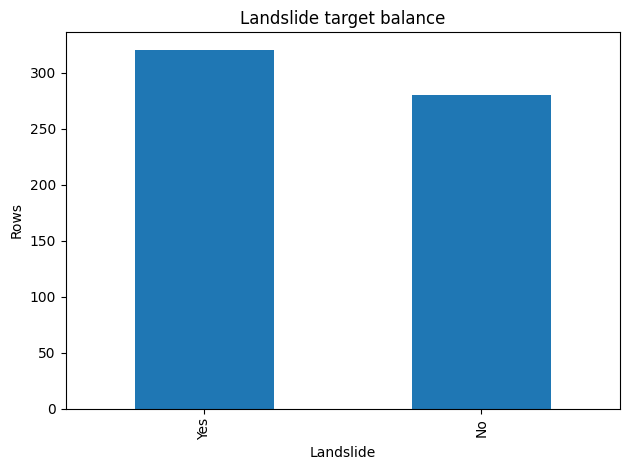

In [29]:
df.info()
display(df.isna().sum().to_frame("missing_count"))
display(df["Landslide"].value_counts(dropna=False).to_frame("count"))
df["Landslide"].value_counts().plot(kind="bar", title="Landslide target balance")
plt.xlabel("Landslide"); plt.ylabel("Rows"); plt.tight_layout(); plt.show()


## 3. Inspect duplicates and suspicious values

In [30]:
feature_label_cols = [
    "Max_Temp_C", "Humidity_Pct", "Wind_Speed_kmh",
    "Rainfall_mm", "Slope_Angle_Deg", "Vegetation_Cover", "Landslide"
]
print("Repeated rows when Location_ID is ignored:", df.duplicated(subset=feature_label_cols).sum())
display(df[["Max_Temp_C", "Humidity_Pct", "Wind_Speed_kmh", "Rainfall_mm", "Slope_Angle_Deg"]].describe().T)
print("Humidity below 30% — verify against original source:")
display(df.loc[df["Humidity_Pct"] < 30, ["Location_ID", "Humidity_Pct", "Rainfall_mm", "Landslide"]].head(20))


Repeated rows when Location_ID is ignored: 454


,count,mean,std,min,25%,50%,75%,max
Max_Temp_C,600.0,28.732667,2.407265,24.5,26.8,28.50,30.7,33.4
Humidity_Pct,600.0,76.107333,26.038041,17.7,74.0,86.00,93.0,99.0
Wind_Speed_kmh,600.0,12.700000,8.769921,1.0,6.0,11.00,18.0,32.0
Rainfall_mm,600.0,116.445333,100.146581,0.0,14.0,101.15,198.0,330.0
Slope_Angle_Deg,600.0,29.606667,12.704368,8.0,17.0,32.50,40.0,52.0


Humidity below 30% — verify against original source:


,Location_ID,Humidity_Pct,Rainfall_mm,Landslide
3,4,19.8,185.0,Yes
4,5,19.2,240.2,Yes
5,6,21.1,65.8,No
8,9,22.6,5.4,No
9,10,21.5,58.1,No
10,11,20.9,92.3,Yes
11,12,19.5,165.4,Yes
12,13,19.1,210.8,Yes
13,14,20.6,61.2,No
14,15,20.2,112.9,Yes


## 4. Prepare features and target

For this exercise, drop duplicate feature/target rows to reduce repeated-record leakage in a random split. For a real dataset, prefer a time-based or location/group-based evaluation where appropriate. Preprocessing is kept inside a pipeline to avoid fitting transformations on test data.


In [31]:
df = df.copy()
df["Landslide"] = df["Landslide"].astype(str).str.strip().str.title()
df = df[df["Landslide"].isin(["Yes", "No"])].copy()
feature_label_cols = [
    "Max_Temp_C", "Humidity_Pct", "Wind_Speed_kmh",
    "Rainfall_mm", "Slope_Angle_Deg", "Vegetation_Cover", "Landslide"
]
before = len(df)
df = df.drop_duplicates(subset=feature_label_cols).reset_index(drop=True)
print(f"Rows before de-duplication: {before}; after: {len(df)}")

X = df.drop(columns=["Location_ID", "Landslide"], errors="ignore")
y = df["Landslide"].map({"No": 0, "Yes": 1})
print("Features:", X.columns.tolist())
display(y.value_counts().sort_index().rename(index={0:"No", 1:"Yes"}).to_frame("count"))


Rows before de-duplication: 600; after: 146
Features: ['Max_Temp_C', 'Humidity_Pct', 'Wind_Speed_kmh', 'Rainfall_mm', 'Slope_Angle_Deg', 'Vegetation_Cover']


,count
Landslide,
No,66
Yes,80


## 5. Split data and build preprocessing/model pipeline

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced"))
])
print("Train rows:", len(X_train), "| Test rows:", len(X_test))


Train rows: 116 | Test rows: 30


## 6. Train and evaluate
Do not rely on accuracy alone. Recall for the `Yes` class and false negatives are important to inspect.

Accuracy: 1.0
Balanced accuracy: 1.0
\nClassification report:
              precision    recall  f1-score   support

No landslide       1.00      1.00      1.00        14
   Landslide       1.00      1.00      1.00        16

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



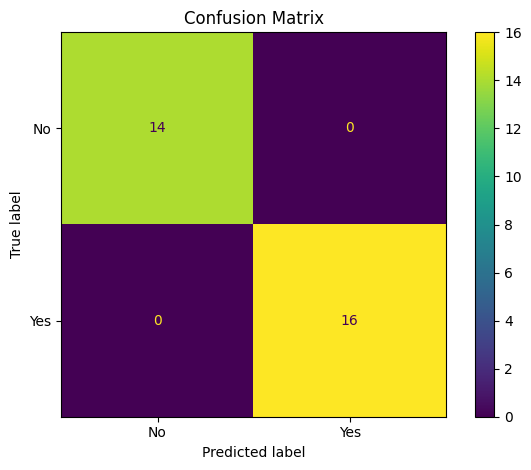

In [33]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
print("\\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["No landslide", "Landslide"], zero_division=0))
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No", "Yes"]).plot()
plt.title("Confusion Matrix"); plt.tight_layout(); plt.show()


## 7. Compare with a majority-class baseline

In [34]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
print("Baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("Logistic Regression accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Compare recall and F1 too; majority-class prediction is not a useful warning system.")


Baseline accuracy: 0.5333
Logistic Regression accuracy: 1.0
Compare recall and F1 too; majority-class prediction is not a useful warning system.


## 8. Predict a sample

In [35]:
sample = pd.DataFrame([{
    "Max_Temp_C": 28.1,
    "Humidity_Pct": 92,
    "Wind_Speed_kmh": 12,
    "Rainfall_mm": 120.4,
    "Slope_Angle_Deg": 35,
    "Vegetation_Cover": "Low"
}])
pred = int(model.predict(sample)[0])
prob = float(model.predict_proba(sample)[0][1])
print("Predicted label:", "Yes" if pred == 1 else "No")
print(f"Model-estimated probability for class Yes: {prob:.3f}")
print("Prototype output only — not an official warning.")


Predicted label: Yes
Model-estimated probability for class Yes: 0.952
Prototype output only — not an official warning.


## 9. Save the full preprocessing + model pipeline

In [36]:
import joblib
MODEL_PATH = Path("landslide_logistic_pipeline.joblib")
joblib.dump(model, MODEL_PATH)
print("Saved to:", MODEL_PATH.resolve())


Saved to: C:\Users\91904\Desktop\ksfe\AI\CODE\Django_React_AI_project\wayanad-landslide-early-warning-system\notebooks\landslide_logistic_pipeline.joblib


## 10. Harness Engineering — validation and controlled prediction

Harness Engineering adds explicit context, input rules, tools, tests, logging, and safe failure behavior around an AI/ML workflow. This example does not send email.


In [37]:
REQUIRED_FIELDS = [
    "Max_Temp_C", "Humidity_Pct", "Wind_Speed_kmh",
    "Rainfall_mm", "Slope_Angle_Deg", "Vegetation_Cover"
]
NUMERIC_RANGES = {
    "Max_Temp_C": (-10, 60),
    "Humidity_Pct": (0, 100),
    "Wind_Speed_kmh": (0, 250),
    "Rainfall_mm": (0, 2000),
    "Slope_Angle_Deg": (0, 90),
}

def validate_observation(payload):
    missing = [field for field in REQUIRED_FIELDS if field not in payload]
    if missing:
        raise ValueError(f"Missing required fields: {missing}")
    for field, (low, high) in NUMERIC_RANGES.items():
        value = payload[field]
        if not isinstance(value, (int, float)) or not low <= value <= high:
            raise ValueError(f"{field} must be a number between {low} and {high}")
    if payload["Vegetation_Cover"] not in {"Low", "Medium", "High"}:
        raise ValueError("Vegetation_Cover must be Low, Medium, or High")
    return True

def predict_observation(payload, trained_model=model):
    validate_observation(payload)
    row = pd.DataFrame([payload])
    pred = int(trained_model.predict(row)[0])
    prob = float(trained_model.predict_proba(row)[0][1])
    return {
        "prediction": "Yes" if pred else "No",
        "probability": round(prob, 4),
        "prototype_only": True,
        "notification_status": "NOT_SENT — manual review required"
    }

print(predict_observation(sample.iloc[0].to_dict()))


{'prediction': 'Yes', 'probability': 0.9515, 'prototype_only': True, 'notification_status': 'NOT_SENT — manual review required'}


## 11. Harness verification tests

In [38]:
valid_payload = sample.iloc[0].to_dict()
assert validate_observation(valid_payload) is True

bad = dict(valid_payload)
bad["Humidity_Pct"] = 140
try:
    validate_observation(bad)
    raise AssertionError("Invalid humidity should fail")
except ValueError:
    print("PASS: invalid humidity rejected")

missing = dict(valid_payload)
missing.pop("Rainfall_mm")
try:
    validate_observation(missing)
    raise AssertionError("Missing field should fail")
except ValueError:
    print("PASS: missing field rejected")

print("PASS: basic harness checks completed")


PASS: invalid humidity rejected
PASS: missing field rejected
PASS: basic harness checks completed


## 12. Jev AI — optional structured decision-support evaluation

Jev AI was requested as a project component. This notebook does not assume an undocumented package, API endpoint, or capability. Verify the official documentation, supported input/output schema, authentication, and availability before implementing a live connection.

**Proposed role:** evaluate Jev AI for a narrowly defined structured decision-support task after the ML prediction. It must not replace the classifier or independently trigger public alerts. Validate output against a schema and require human approval before external notifications.

The following is only a sample context object, not a Jev API call.


In [39]:
decision_context = {
    "location_id": 3,
    "ml_prediction": "Yes",
    "ml_probability": 0.82,
    "retrieved_safety_context": ["Insert verified, approved safety guidance here."],
    "allowed_actions": ["record_result", "draft_alert_for_review"],
    "prohibited_actions": ["send_public_alert_without_authorization"]
}
print(json.dumps(decision_context, indent=2))


{
  "location_id": 3,
  "ml_prediction": "Yes",
  "ml_probability": 0.82,
  "retrieved_safety_context": [
    "Insert verified, approved safety guidance here."
  ],
  "allowed_actions": [
    "record_result",
    "draft_alert_for_review"
  ],
  "prohibited_actions": [
    "send_public_alert_without_authorization"
  ]
}


## 13. Implementation roadmap after the notebook

1. Verify dataset quality and obtain more representative observations.
2. Compare models with time/location-aware validation.
3. Create the DRF prediction API and database models.
4. Build React data-entry and result screens.
5. Build RAG document loading, chunking, embeddings, retrieval, and source tracking.
6. Add an LLM that grounds recommendations in retrieved approved documents.
7. Add an AI Agent with narrowly scoped tools, logs, dry-run mode, and human approval.
8. Evaluate Jev AI only after verifying its official interface and suitability.
9. Add Harness Engineering controls: schema validation, timeout/retry limits, duplicate-alert prevention, audit logs, and failure tests.
10. Build Power BI monitoring dashboards.

**Safety reminder:** This is an educational prototype. Do not use predictions for real evacuation or emergency decisions.
